# Домашнее задание
### школа аналитиков HH.RU · Ad-hoc аналитика
#### Иващенко Юлия

#### Контекст

20 июля 2026 года кликабельность формата `top_search` на Android резко выросла. Продакт поиска решает, куда направить работу команды

#### Запрос от продакта

> На Android 20 июля подскочил CTR в топе поиска. Проверяем логирование или есть повод менять формат показа?

| Поле ТЗ | Значение                                                                                                                                                                                                             |
|---|----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Цель | Понять, выдерживает ли всплеск проверку данных и есть ли основания тестировать изменение формата                                                                                                                     |
| Гипотеза | Скачок могли создать лишние записи кликов. Другие возможные объяснения — изменение поведения пользователей или состава трафика                                                                                       |
| Метрика | CTR — доля показов с кликом. CVR — доля показов с откликом среди показов с кликом. Целевая конверсия — доля показов с откликом среди всех показов. Будем учитывать только отклики, связанные с кликом того же показа |
| Период | сравним 20 июля с остальными днями 15–28 июля. Для проверки устойчивости сравним также с периодом 1–28 июля без 20-го                                                                                                |
| Сегменты | Основной срез — Android и `top_search`. Для диагностики смотрим `top_search` на других платформах, `top_boost` на Android и три сегмента работодателей в основном срезе                                              |
| Критерий | День уходит на проверку, если CTR выше максимума остальных 13 дней основной базы. Если всплеск исчезает после подсчёта по уникальным показам или видны ошибки связей, начинаем с логирования                         |
| Решение | Куда направим силы: в исправление дефекта, при корректном трекинге в проверку А/В тестами                                                                                                                            |
| Глубина | Разбор: правка формата займёт время команды и может повлиять на отклики. Саму правку можно откатить, но до отката часть пользователей уже увидит изменённую выдачу                                                   |

Данные — синтетические `impressions.csv`, `clicks.csv`, `responses.csv` из папки `data/`


#### Подготовка окружения

In [23]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import warnings

# Доустанавливаем недостающие пакеты (нужно только при первом запуске).
_required = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "duckdb": "duckdb",
}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Устанавливаю пакеты:", ", ".join(_missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import duckdb


warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Ищем папку data/ рядом с ноутбуком, выше по дереву или в подпапке.
def find_data_dir(marker: str = "impressions.csv") -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data" / marker).is_file():
            return base / "data"
    for path in here.glob("**/data/" + marker):
        if path.is_file():
            return path.parent
    raise FileNotFoundError(
        f"Не найдена папка data/ с файлом {marker}. "
        "Положи папку data/ рядом с Ad_hoc.ipynb."
    )

DATA = find_data_dir()
print("Данные:", DATA)

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL.
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # Сохраняем год, месяц и день как строки для фильтров вроде day BETWEEN '01' AND '28'.
    for col in ("year", "month", "day"):
        if col in df.columns:
            df[col] = df[col].astype("Int64").astype("string")
            if col != "year":
                df[col] = df[col].str.zfill(2)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполняем SQL-запрос к синтетическим таблицам.
    return con.execute(query).df()

from pandas.io.formats.style import Styler

print("\nГотово. Для запросов используйте функцию sql('''...''').")


Данные: /Users/julia/Documents/hh-hw/HW8_ad_hoc/data
impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv

Готово. Для запросов используйте функцию sql('''...''').


#### Параметры и функции для ad-hoc

In [24]:
# Параметры сравнения для этой домашки.
target_day = "2026-07-20"
baseline_start = "2026-07-15"
day_label = "20 июля"
baseline_label = "15–28 июля без 20-го"
full_baseline_label = "1–28 июля без 20-го"
counts = ["impressions", "clicks", "responses"]

def summarize_dq(df, key_cols):
    # Быстрая сводка по качеству данных
    return {
        "строк": len(df),
        "пропусков": int(df.isna().sum().sum()),
        "полных дублей": int(df.duplicated().sum()),
        "дублей по ключу": int(df.duplicated(key_cols).sum()),
        "дней": df["event_date"].nunique(),
        "первая дата": df["event_date"].min(),
        "последняя дата": df["event_date"].max(),
    }

def wilson_ci(successes, n, z=1.96):
    # Доверительный интервал для доли по методу Уилсона
    if n <= 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return max(0.0, center - margin), min(1.0, center + margin)

def proportion_table(df, group_cols, success_col, n_col, rate_name="rate"):
    #Таблица долей с интервалами по группам
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    intervals = g.apply(lambda row: wilson_ci(row["successes"], row["n"]), axis=1)
    g["ci_low"] = intervals.map(lambda bounds: bounds[0])
    g["ci_high"] = intervals.map(lambda bounds: bounds[1])
    return g

#### Проверка качества данных
Смотрим пропуски, дубли по ID, покрытие дат и связи между таблицами. Клик должен вести к существующему показу, а отклик — к клику того же показа

Уникальные `click_id` сами по себе не исключают повторного логирования. Если одной записи присвоили новый `click_id`, она всё равно может ссылаться на тот же `impression_id`. Поэтому сравним число строк кликов и число разных показов, к которым они относятся

In [25]:
quality = pd.DataFrame.from_dict({
    "Показы": summarize_dq(impressions, ["impression_id"]),
    "Клики": summarize_dq(clicks, ["click_id"]),
    "Отклики": summarize_dq(responses, ["response_id"]),
}, orient="index")
display(quality)

q_links = '''
SELECT
    'клик -> показ' AS step,
    COUNT(*) - COUNT(i.impression_id) AS missing_parent,
    COUNT(*) FILTER (
        WHERE i.impression_id IS NOT NULL
          AND ROW(c.event_date, c.platform, c.product, c.segment,
                  c.hhuid, c.vacancy_id, c.employer_id)
              IS DISTINCT FROM
              ROW(i.event_date, i.platform, i.product, i.segment,
                  i.hhuid, i.vacancy_id, i.employer_id)
    ) AS mismatched_fields
FROM clicks AS c
LEFT JOIN impressions AS i ON c.impression_id = i.impression_id

UNION ALL

SELECT
    'отклик -> клик' AS step,
    COUNT(*) - COUNT(c.click_id) AS missing_parent,
    COUNT(*) FILTER (
        WHERE c.click_id IS NOT NULL
          AND ROW(r.impression_id, r.event_date, r.platform, r.product, r.segment,
                  r.hhuid, r.vacancy_id, r.employer_id)
              IS DISTINCT FROM
              ROW(c.impression_id, c.event_date, c.platform, c.product, c.segment,
                  c.hhuid, c.vacancy_id, c.employer_id)
    ) AS mismatched_fields
FROM responses AS r
LEFT JOIN clicks AS c ON r.click_id = c.click_id
'''

links = sql(q_links)
display(links)

print("Повторные impression_id среди кликов:", clicks["impression_id"].duplicated().sum())
print("Повторные impression_id среди откликов:", responses["impression_id"].duplicated().sum())

target_clicks = sql('''
SELECT COUNT(*) AS click_rows, COUNT(DISTINCT impression_id) AS clicked_impressions
FROM clicks
WHERE event_date = '2026-07-20' AND platform = 'ANDROID' AND product = 'top_search'
''')
display(target_clicks)

,строк,пропусков,полных дублей,дублей по ключу,дней,первая дата,последняя дата
Показы,80000,0,0,0,28,2026-07-01,2026-07-28
Клики,3837,0,0,0,28,2026-07-01,2026-07-28
Отклики,421,0,0,0,28,2026-07-01,2026-07-28


,step,missing_parent,mismatched_fields
0,клик -> показ,0,0
1,отклик -> клик,0,0


Повторные impression_id среди кликов: 0
Повторные impression_id среди откликов: 0


,click_rows,clicked_impressions
0,36,36


#### Запрос. Дневная воронка по платформам и продуктам

В выгрузках есть 80 000 показов, 3 837 кликов и 421 отклик. Пропусков, дублей по ID и ошибок в проверенных связях нет. Все 36 кликов 20 июля относятся к разным показам, поэтому при подсчёте по уникальным показам скачок сохраняется. Воронку начнём с показов, потому что они в знаменателе CTR. LEFT JOIN позволит сохранить и показы без кликов

In [26]:
q_funnel = '''
WITH clk AS (
    SELECT DISTINCT impression_id
    FROM clicks
),
rsp AS (
    SELECT DISTINCT r.impression_id
    FROM responses AS r
    JOIN clicks AS c
      ON r.click_id = c.click_id AND r.impression_id = c.impression_id
)
SELECT
    i.event_date,
    i.platform,
    i.product,
    i.segment,
    COUNT(*) AS impressions,
    COUNT(c.impression_id) AS clicks,
    COUNT(r.impression_id) AS responses
FROM impressions AS i
LEFT JOIN clk AS c ON i.impression_id = c.impression_id
LEFT JOIN rsp AS r ON i.impression_id = r.impression_id
WHERE i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2, 3, 4
ORDER BY 1, 2, 3, 4
'''

daily_by_segment = sql(q_funnel)
assert (daily_by_segment["responses"] <= daily_by_segment["clicks"]).all()
assert (daily_by_segment["clicks"] <= daily_by_segment["impressions"]).all()
display(daily_by_segment.head())

,event_date,platform,product,segment,impressions,clicks,responses
0,2026-07-01,ANDROID,top_search,Large,181,5,1
1,2026-07-01,ANDROID,top_search,Premium,95,3,0
2,2026-07-01,ANDROID,top_search,SMB,323,8,2
3,2026-07-01,DESKTOP_WEB,top_search,Large,292,18,2
4,2026-07-01,DESKTOP_WEB,top_search,Premium,149,14,1


#### Сравнение, что произошло 20 июля

В основной базе складываем показы и клики по всем 13 дням и только потом делим. Так день с большим числом показов имеет больший вес. Для графика распределения каждый день получит свой CTR и станет одной точкой.

Сначала смотрим всю воронку Android `top_search`. Затем проверяем, встречается ли рост у других продуктов и платформ и сохраняется ли он в сегментах работодателей

In [27]:
def add_rates(df):
    return df.assign(
        ctr=df["clicks"] / df["impressions"],
        cvr=df["responses"] / df["clicks"].replace(0, np.nan),
        response_rate=df["responses"] / df["impressions"],
    )

daily = add_rates(
    daily_by_segment.groupby(["event_date", "platform", "product"], as_index=False)[counts].sum()
)
android = daily.query("platform == 'ANDROID' and product == 'top_search'").set_index("event_date")
other_days = android.loc[android.index >= baseline_start].drop(index=target_day)
all_other_days = android.drop(index=target_day)

funnel = add_rates(pd.DataFrame({
    baseline_label: other_days[counts].sum(),
    day_label: android.loc[target_day, counts],
    full_baseline_label: all_other_days[counts].sum(),
}).T.astype(int)).rename_axis("period")

display(funnel.style.format({
    "ctr": "{:.2%}", "cvr": "{:.2%}", "response_rate": "{:.2%}",
}))

recent = daily_by_segment.loc[daily_by_segment["event_date"].ge(baseline_start)].copy()
recent["period"] = np.where(recent["event_date"].eq(target_day), day_label, baseline_label)

slices = add_rates(recent.groupby(["product", "platform", "period"])[counts].sum())
display(slices["ctr"].unstack("period")[[baseline_label, day_label]].style.format("{:.2%}"))

android_search = recent.query("platform == 'ANDROID' and product == 'top_search'")
segments = add_rates(android_search.groupby(["segment", "period"])[counts].sum())
display(segments["ctr"].unstack("period")[[baseline_label, day_label]].style.format("{:.2%}"))

,impressions,clicks,responses,ctr,cvr,response_rate
period,,,,,,
15–28 июля без 20-го,4990,147,22,2.95%,14.97%,0.44%
20 июля,383,36,4,9.40%,11.11%,1.04%
1–28 июля без 20-го,13898,444,63,3.19%,14.19%,0.45%


period,15–28 июля без 20-го,20 июля
segment,,
Large,2.88%,10.81%
Premium,3.60%,6.45%
SMB,2.79%,9.52%


**Воронка**. CTR вырос с 2,95% до 9,40%. При этом доля откликов среди показов с кликом снизилась с 14,97% до 11,11%. За 20 июля было всего четыре отклика, поэтому по одному дню рано судить, стал ли формат лучше

**Платформы и продукты**. В тот же день CTR вырос у `top_boost` на Android с 4,43% до 11,51%, а у `top_search` в мобильном вебе — с 4,89% до 7,88%. На iOS CTR `top_search` остался около 3%. При проверке событий стоит посмотреть и Android, и мобильный веб

**Сегменты**. CTR вырос во всех трёх группах работодателей. Например, у Large — с 2,88% до 10,81%, у SMB — с 2,79% до 9,52%. Одним перераспределением показов между этими группами скачок не объясняется

####  График с интервалами Уилсона

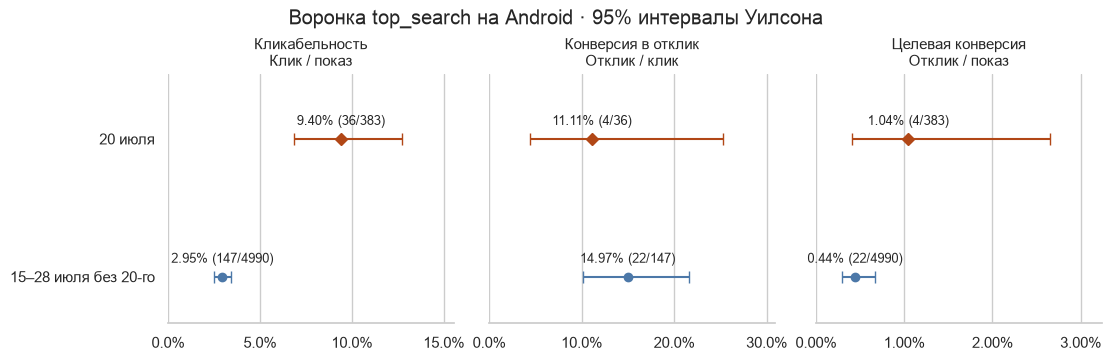

In [28]:
from matplotlib.ticker import PercentFormatter

plot_df = funnel.loc[[baseline_label, day_label]].reset_index()
metrics = [
    ("Кликабельность\nКлик / показ", "clicks", "impressions"),
    ("Конверсия в отклик\nОтклик / клик", "responses", "clicks"),
    ("Целевая конверсия\nОтклик / показ", "responses", "impressions"),
]
palette = {baseline_label: "#4C78A8", day_label: "#B14716"}
response_ci = proportion_table(plot_df, ["period"], "responses", "impressions").set_index("period")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True, layout="constrained")
for ax, (title, success_col, n_col) in zip(axes, metrics):
    ci = proportion_table(plot_df, ["period"], success_col, n_col).set_index("period")
    for y, period in enumerate([baseline_label, day_label]):
        row = ci.loc[period]
        rate = row["rate"]
        ax.errorbar(
            rate, y, xerr=[[rate - row["ci_low"]], [row["ci_high"] - rate]],
            fmt="o" if y == 0 else "D", color=palette[period], capsize=4,
        )
        ax.annotate(
            f"{rate:.2%} ({int(row['successes'])}/{int(row['n'])})",
            (rate, y), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9,
        )
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, ci["ci_high"].max() * 1.22)
    ax.set_ylim(-0.34, 1.47)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)

axes[0].set_yticks([0, 1], [baseline_label, day_label])
fig.suptitle("Воронка top_search на Android · 95% интервалы Уилсона")
plt.show()

#### Распределение дневного CTR
Коробка показывает разброс, каждая точка — один день. 20 июля исключаем из коробок и показываем отдельно ромбами

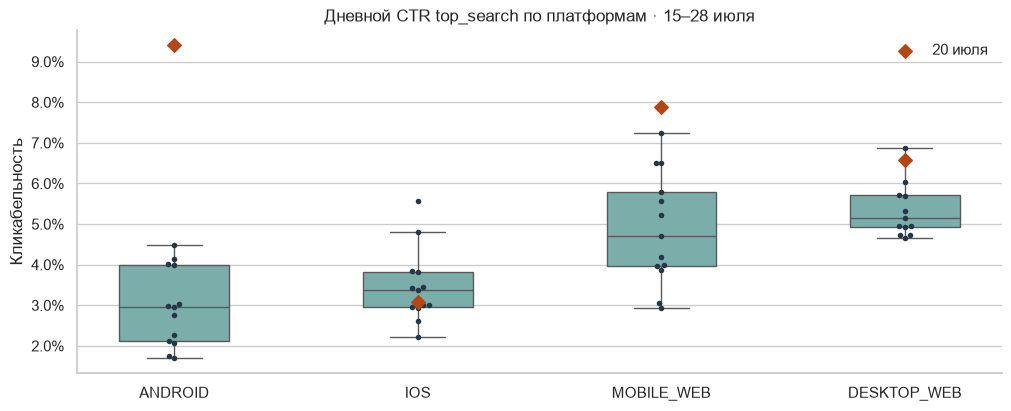

Дни с самым высоким CTR на Android:


,impressions,clicks,responses,ctr
event_date,,,,
2026-07-20,383,36,4,9.40%
2026-07-27,380,17,3,4.47%
2026-07-09,598,26,4,4.35%


In [29]:
top_search = daily.loc[daily["product"].eq("top_search")]
baseline_daily = top_search.loc[
    top_search["event_date"].ge(baseline_start) & top_search["event_date"].ne(target_day)
]
platform_order = ["ANDROID", "IOS", "MOBILE_WEB", "DESKTOP_WEB"]
target_ctr = top_search.loc[top_search["event_date"].eq(target_day)].set_index("platform")["ctr"]

fig, ax = plt.subplots(layout="constrained")
sns.boxplot(
    data=baseline_daily, x="platform", y="ctr", order=platform_order,
    color="#72B7B2", showfliers=False, width=0.45, ax=ax,
)
sns.swarmplot(
    data=baseline_daily, x="platform", y="ctr", order=platform_order,
    color="#263746", size=4, ax=ax,
)
ax.scatter(
    range(len(platform_order)), target_ctr.reindex(platform_order),
    marker="D", color=palette[day_label], s=48, label=day_label, zorder=5,
)
ax.set(
    title="Дневной CTR top_search по платформам · 15–28 июля",
    xlabel="", ylabel="Кликабельность",
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=False)
sns.despine(ax=ax)
plt.show()

print("Дни с самым высоким CTR на Android:")
display(android.nlargest(3, "ctr")[counts + ["ctr"]].style.format({"ctr": "{:.2%}"}))

### После разбора

20 июля CTR был самым высоким за 1–28 июля. Следующий по величине результат это 4,47% 27 июля, когда показов было почти столько же: 380 против 383. Я бы пока оставила формат как есть и сначала сверила клики за 20 июля с сырыми логами

#### Итоговая справка

In [30]:
from IPython.display import Markdown

def one_pager(decision, context, what_done, result, limits, action):
    return f"""## Итоговая справка · top_search на Android, 20 июля 2026

**Решение.** {decision}

**Контекст.** {context}

**Что сделали.** {what_done}

**Результат.** {result}

**Ограничения.** {limits}

**Следующий шаг.** {action}"""

day = funnel.loc[day_label]
baseline = funnel.loc[baseline_label]
day_interval = response_ci.loc[day_label]
note = one_pager(
    decision="Пока сохраняем формат показа. В первую очередь сверяем события 20 июля с сырыми логами.",
    context="Продакт поиска увидел скачок CTR формата top_search на Android.",
    what_done=(
        "Сравнили 20 июля с остальными днями 15–28 июля. Проверили дубли и связи, "
        "построили воронку с 95% интервалами Уилсона и распределение дневного CTR."
    ),
    result=(
        f"CTR составил {day['ctr']:.2%} ({int(day['clicks'])}/{int(day['impressions'])}) "
        f"против {baseline['ctr']:.2%} ({int(baseline['clicks'])}/{int(baseline['impressions'])}). "
        "Все 36 кликов относятся к разным показам. "
        f"Конверсия из показа в отклик — {day['response_rate']:.2%} "
        f"против {baseline['response_rate']:.2%}. "
        f"За 20 июля всего четыре отклика, 95% интервал — "
        f"от {day_interval['ci_low']:.2%} до {day_interval['ci_high']:.2%}."
    ),
    limits=(
        "В выгрузке нет времени внутри дня, версии приложения, источника трафика "
        "и независимого журнала для сверки. Возможны ошибки логирования с корректными ID "
        "и пропуск отложенных откликов. Сравнение наблюдательное. Интервалы предполагают "
        "независимость показов."
    ),
    action=(
        "До решения о релизе аналитик и команда Android сверяют клиентские и серверные события, "
        "продакт проверяет релизы и изменения трафика. Если найден дефект, команда исправляет "
        "трекинг, аналитик пересчитывает воронку. Если трекинг корректен и найдено изменение "
        "формата, проверяем его A/B-тестом по конверсии из показа в отклик."
    ),
)
display(Markdown(note))

## Итоговая справка · top_search на Android, 20 июля 2026

**Решение.** Пока сохраняем формат показа. В первую очередь сверяем события 20 июля с сырыми логами.

**Контекст.** Продакт поиска увидел скачок CTR формата top_search на Android.

**Что сделали.** Сравнили 20 июля с остальными днями 15–28 июля. Проверили дубли и связи, построили воронку с 95% интервалами Уилсона и распределение дневного CTR.

**Результат.** CTR составил 9.40% (36/383) против 2.95% (147/4990). Все 36 кликов относятся к разным показам. Конверсия из показа в отклик — 1.04% против 0.44%. За 20 июля всего четыре отклика, 95% интервал — от 0.41% до 2.65%.

**Ограничения.** В выгрузке нет времени внутри дня, версии приложения, источника трафика и независимого журнала для сверки. Возможны ошибки логирования с корректными ID и пропуск отложенных откликов. Сравнение наблюдательное. Интервалы предполагают независимость показов.

**Следующий шаг.** До решения о релизе аналитик и команда Android сверяют клиентские и серверные события, продакт проверяет релизы и изменения трафика. Если найден дефект, команда исправляет трекинг, аналитик пересчитывает воронку. Если трекинг корректен и найдено изменение формата, проверяем его A/B-тестом по конверсии из показа в отклик.

#### _бонус_

#### Расходы до и после 15 июля

In [31]:
product_daily = register_csv("product_daily", "product_daily.csv")

spend = sql('''
SELECT
    CASE WHEN event_date < '2026-07-15' THEN '1–14 июля' ELSE '15–28 июля' END AS period,
    product,
    ROUND(SUM(net_spend) / 1000000, 2) AS net_spend_mln
FROM product_daily
WHERE event_date BETWEEN '2026-07-01' AND '2026-07-28'
GROUP BY 1, 2
ORDER BY 1, 2
''')
display(spend)

product_daily                     252 строк  <- product_daily.csv


,period,product,net_spend_mln
0,15–28 июля,top_boost,2.86
1,15–28 июля,top_search,8.02
2,1–14 июля,top_search,9.84


С 1 по 14 июля расход `top_search` составил 9,84 млн, с 15 по 28 июля — 8,02 млн (−18,45%). С 15 июля в данных появился `top_boost` с расходом 2,86 млн. Разный набор продуктов до и после запуска объясняет, почему основную базу для сравнения взяли с 15 июля. В выгрузке расходов нет разбивки по платформе и связей с показами, поэтому причина скачка CTR из этих сумм неизвестна